# Tarea 1 — Caracterización espectral y prototipado de filtros

CE 1110 — Análisis de Señales Mixtas · Instituto Tecnológico de Costa Rica

Este notebook regenera desde cero las señales de los tres casos de prueba, las
figuras y las métricas del informe. No depende de ningún archivo que no esté en
el repositorio: todos los parámetros salen de `metadatos/configuraciones.json`
y toda la aleatoriedad está fijada por las semillas que ahí se declaran.

Orden de ejecución: de arriba hacia abajo, una sola vez.

## 0. Entorno y configuración

In [1]:
import json
import sys
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image, display
from scipy import signal

RAIZ = Path.cwd()
sys.path.insert(0, str(RAIZ / 'src'))

import dft_fft
import filtros_temporales as ft
import graficas
import metricas
import senales

COMUN, CASOS = senales.cargar_configuracion()
CARPETA_FIGURAS = RAIZ / 'resultados' / 'figuras'

print(f"fs = {COMUN['fs_hz']} Hz | N total = {COMUN['muestras']} | bloque = {COMUN['n_bloque']}")
print(f"resolucion por bloque: {COMUN['fs_hz']/COMUN['n_bloque']:.2f} Hz | "
      f"latencia: {1000*COMUN['n_bloque']/COMUN['fs_hz']:.1f} ms")
print('casos:', list(CASOS))

/home/chago/Documents/Git/Proyecto-Grupal-1-ASM/.venv/lib/python3.11/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


fs = 16000 Hz | N total = 32768 | bloque = 1024
resolucion por bloque: 15.62 Hz | latencia: 64.0 ms
casos: ['caso_1', 'caso_2', 'caso_3']


## 1. Fundamentos, muestreo y FFT

Apartado 2.1 del enunciado. Relación entre serie de Fourier, transformada de
Fourier, DFT y FFT; resolución espectral y su compromiso con latencia y memoria;
fuga espectral con ventana rectangular y Hann; simetría conjugada.

*Pendiente — bloque 2.*

## 2. Generación y caracterización de señales

Apartado 2.2. Tres casos reproducibles, cada uno con su semilla y sus archivos
WAV de señal limpia, ruido y señal contaminada. El desarrollo completo está en
`docs/2_2_senales.md`.

### 2.a Parámetros de cada caso

In [2]:
encabezado = f"{'caso':8s} {'semilla':>10s} {'ruido':>8s} {'util (Hz)':>22s} {'SNR obj':>8s}"
print(encabezado); print('-'*len(encabezado))
for identificador, caso in CASOS.items():
    utiles = ', '.join(str(f) for f in caso['frecuencias_utiles_hz'])
    print(f"{identificador:8s} {caso['semilla']:10d} {caso['tipo_ruido']:>8s} "
          f"{utiles:>22s} {caso['snr_objetivo_db']:7.1f} dB")

caso        semilla    ruido              util (Hz)  SNR obj
------------------------------------------------------------
caso_1     20261001    tonal         440, 880, 1320     2.0 dB
caso_2     20261002   blanco         440, 880, 1320     0.0 dB
caso_3     20261003    banda         440, 880, 1320     3.0 dB


### 2.b Generación y verificación de la SNR

La SNR se verifica dos veces: en punto flotante y releyendo los WAV ya cuantizados a 16 bits.

In [3]:
resumen = senales.generar_todos(verbose=False)

print(f"{'caso':8s} {'objetivo':>10s} {'flotante':>10s} {'desde WAV':>10s} {'diferencia':>11s}")
print('-'*53)
for descripcion in resumen:
    diferencia = descripcion['snr_tras_cuantizar_db'] - descripcion['snr_objetivo_db']
    print(f"{descripcion['id']:8s} {descripcion['snr_objetivo_db']:9.4f}  "
          f"{descripcion['snr_obtenida_db']:9.4f}  "
          f"{descripcion['snr_tras_cuantizar_db']:9.4f}  {diferencia:10.4f}")

caso       objetivo   flotante  desde WAV  diferencia
-----------------------------------------------------
caso_1      2.0000     2.0000     1.9999     -0.0001
caso_2      0.0000     0.0000    -0.0003     -0.0003
caso_3      3.0000     3.0000     2.9998     -0.0002


### 2.c Distribución de energía por bandas

In [4]:
BORDES = graficas.BORDES_DE_BANDA
etiquetas = [f'{a}-{b}' for a, b in zip(BORDES[:-1], BORDES[1:])]
print(f"{'caso':8s} " + ' '.join(f'{e:>9s}' for e in etiquetas))
print('-'*(9 + 10*len(etiquetas)))
for identificador in CASOS:
    datos = senales.cargar_caso(identificador)
    reparto = metricas.energia_por_bandas(datos['contaminada'], datos['fs'], BORDES)
    print(f'{identificador:8s} ' + ' '.join(f"{100*r['fraccion']:8.1f}%" for r in reparto))

caso         0-250   250-500  500-1000 1000-2000 2000-4000 4000-8000
---------------------------------------------------------------------
caso_1        0.0%     44.0%     13.3%      4.0%     38.7%      0.0%
caso_2        1.5%     37.7%     13.5%      9.5%     12.9%     25.0%
caso_3        0.0%     47.9%     24.7%     27.3%      0.0%      0.0%


### 2.d Características que permiten identificar el ruido

Planitud espectral y razón pico/mediana. Son las dos que el nodo espectral puede medir solo para escoger su estrategia.

In [5]:
def planitud_espectral(x):
    densidad = np.abs(np.fft.rfft(x*np.hanning(x.size)))**2 + 1e-20
    return float(np.exp(np.mean(np.log(densidad)))/np.mean(densidad))

def pico_sobre_mediana_db(x):
    densidad = np.abs(np.fft.rfft(x*np.hanning(x.size)))**2 + 1e-20
    return float(10*np.log10(densidad.max()/np.median(densidad)))

print(f"{'caso':8s} {'planitud ruido':>15s} {'planitud cont.':>15s} {'pico/mediana':>14s}")
print('-'*55)
for identificador in CASOS:
    datos = senales.cargar_caso(identificador)
    print(f'{identificador:8s} {planitud_espectral(datos["ruido"]):15.2e} '
          f'{planitud_espectral(datos["contaminada"]):15.2e} '
          f'{pico_sobre_mediana_db(datos["contaminada"]):11.1f} dB')

caso      planitud ruido  planitud cont.   pico/mediana
-------------------------------------------------------
caso_1          1.15e-19        1.88e-14       181.4 dB
caso_2          5.56e-01        2.77e-01        40.6 dB
caso_3          3.21e-08        1.08e-08       124.4 dB


### 2.e Qué información no se puede recuperar

SNR medida tono por tono: cuánta energía de ruido cae encima de cada componente útil.

In [6]:
for identificador in CASOS:
    datos = senales.cargar_caso(identificador)
    linea = []
    for f0 in datos['config']['frecuencias_utiles_hz']:
        banda = (f0 - 60, f0 + 60)
        util = metricas.energia_en_banda(datos['limpia'], datos['fs'], banda)
        ruido = metricas.energia_en_banda(datos['ruido'], datos['fs'], banda)
        snr = 10*np.log10(util/(ruido + 1e-20))
        linea.append(f'{f0:5d} Hz: ' + (f'{snr:6.1f} dB' if snr < 80 else '  limpio'))
    print(f'{identificador:8s} | ' + ' | '.join(linea))

caso_1   |   440 Hz:   limpio |   880 Hz:   limpio |  1320 Hz:   limpio
caso_2   |   440 Hz:   16.9 dB |   880 Hz:   12.1 dB |  1320 Hz:    6.1 dB
caso_3   |   440 Hz:   limpio |   880 Hz:    4.2 dB |  1320 Hz:   -0.9 dB


### 2.f Figuras

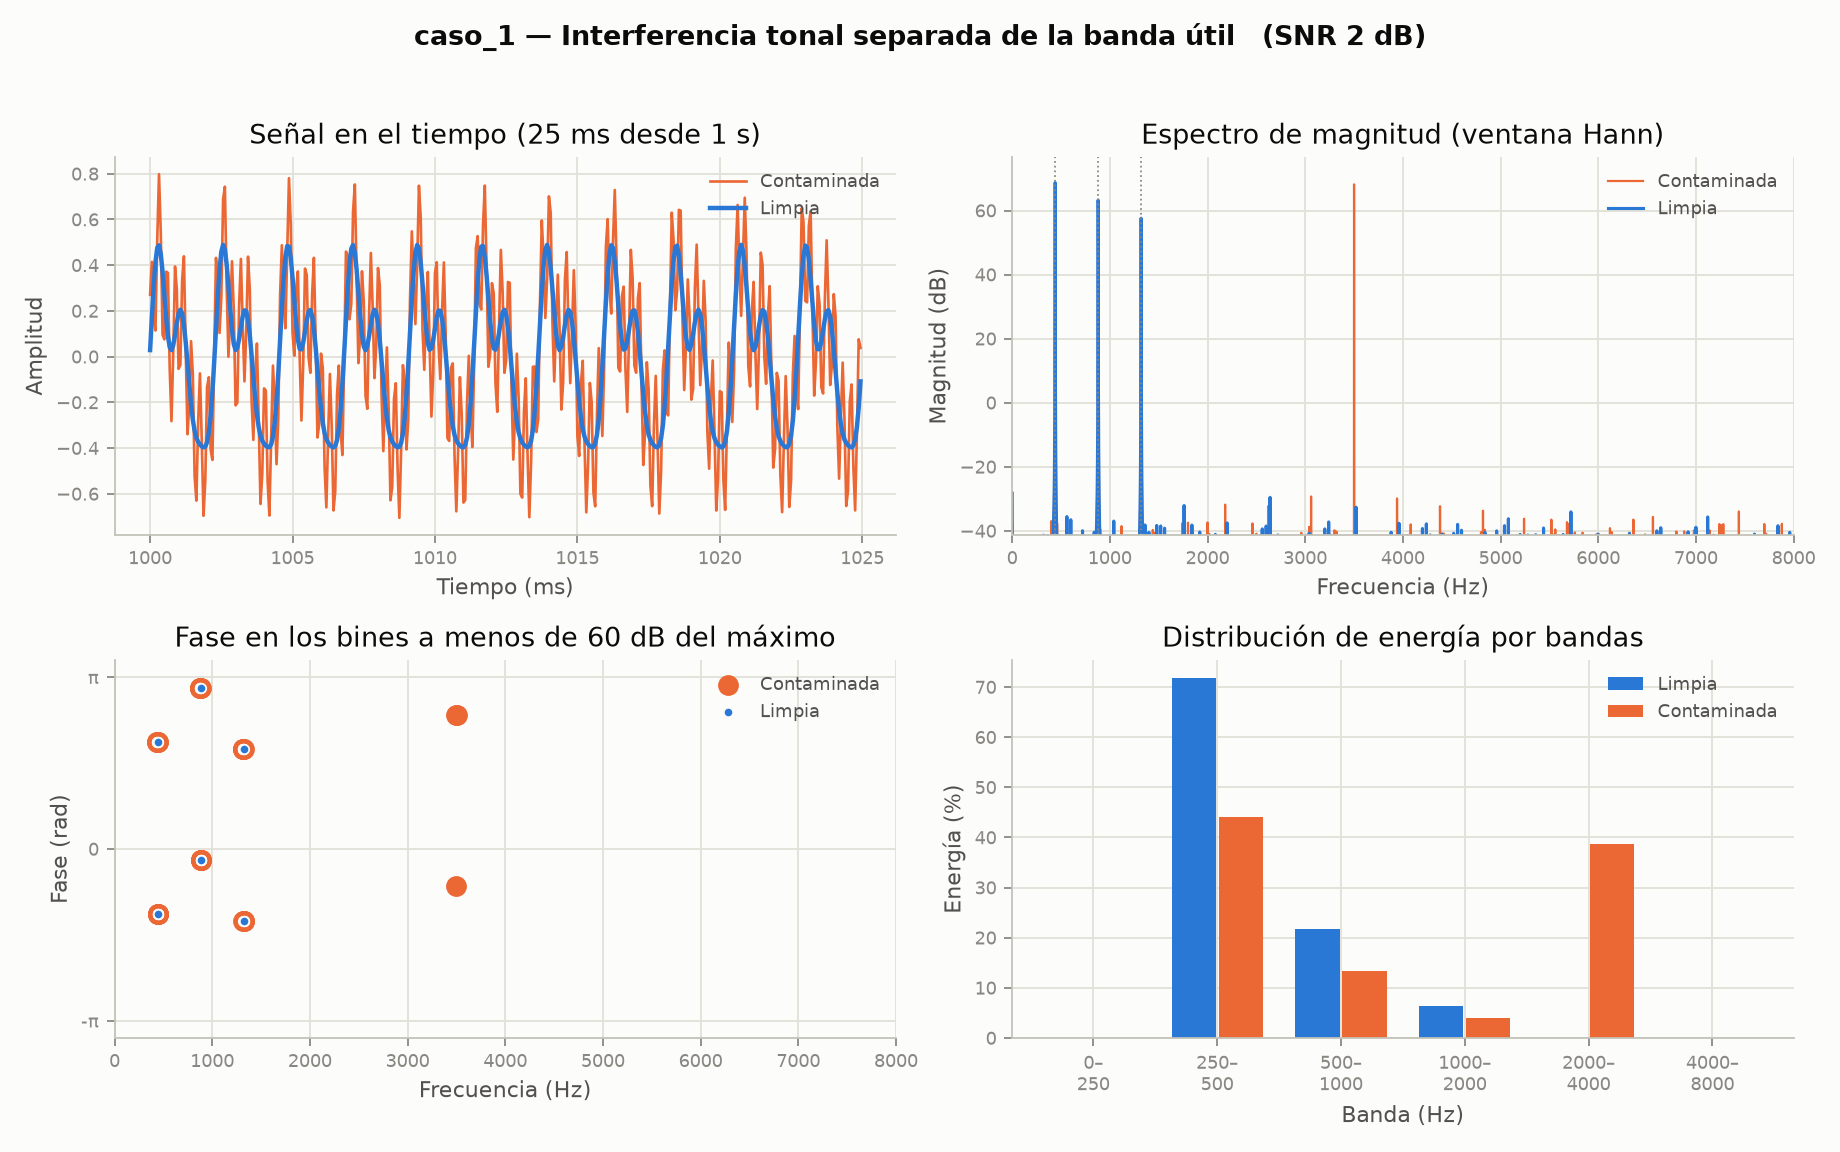

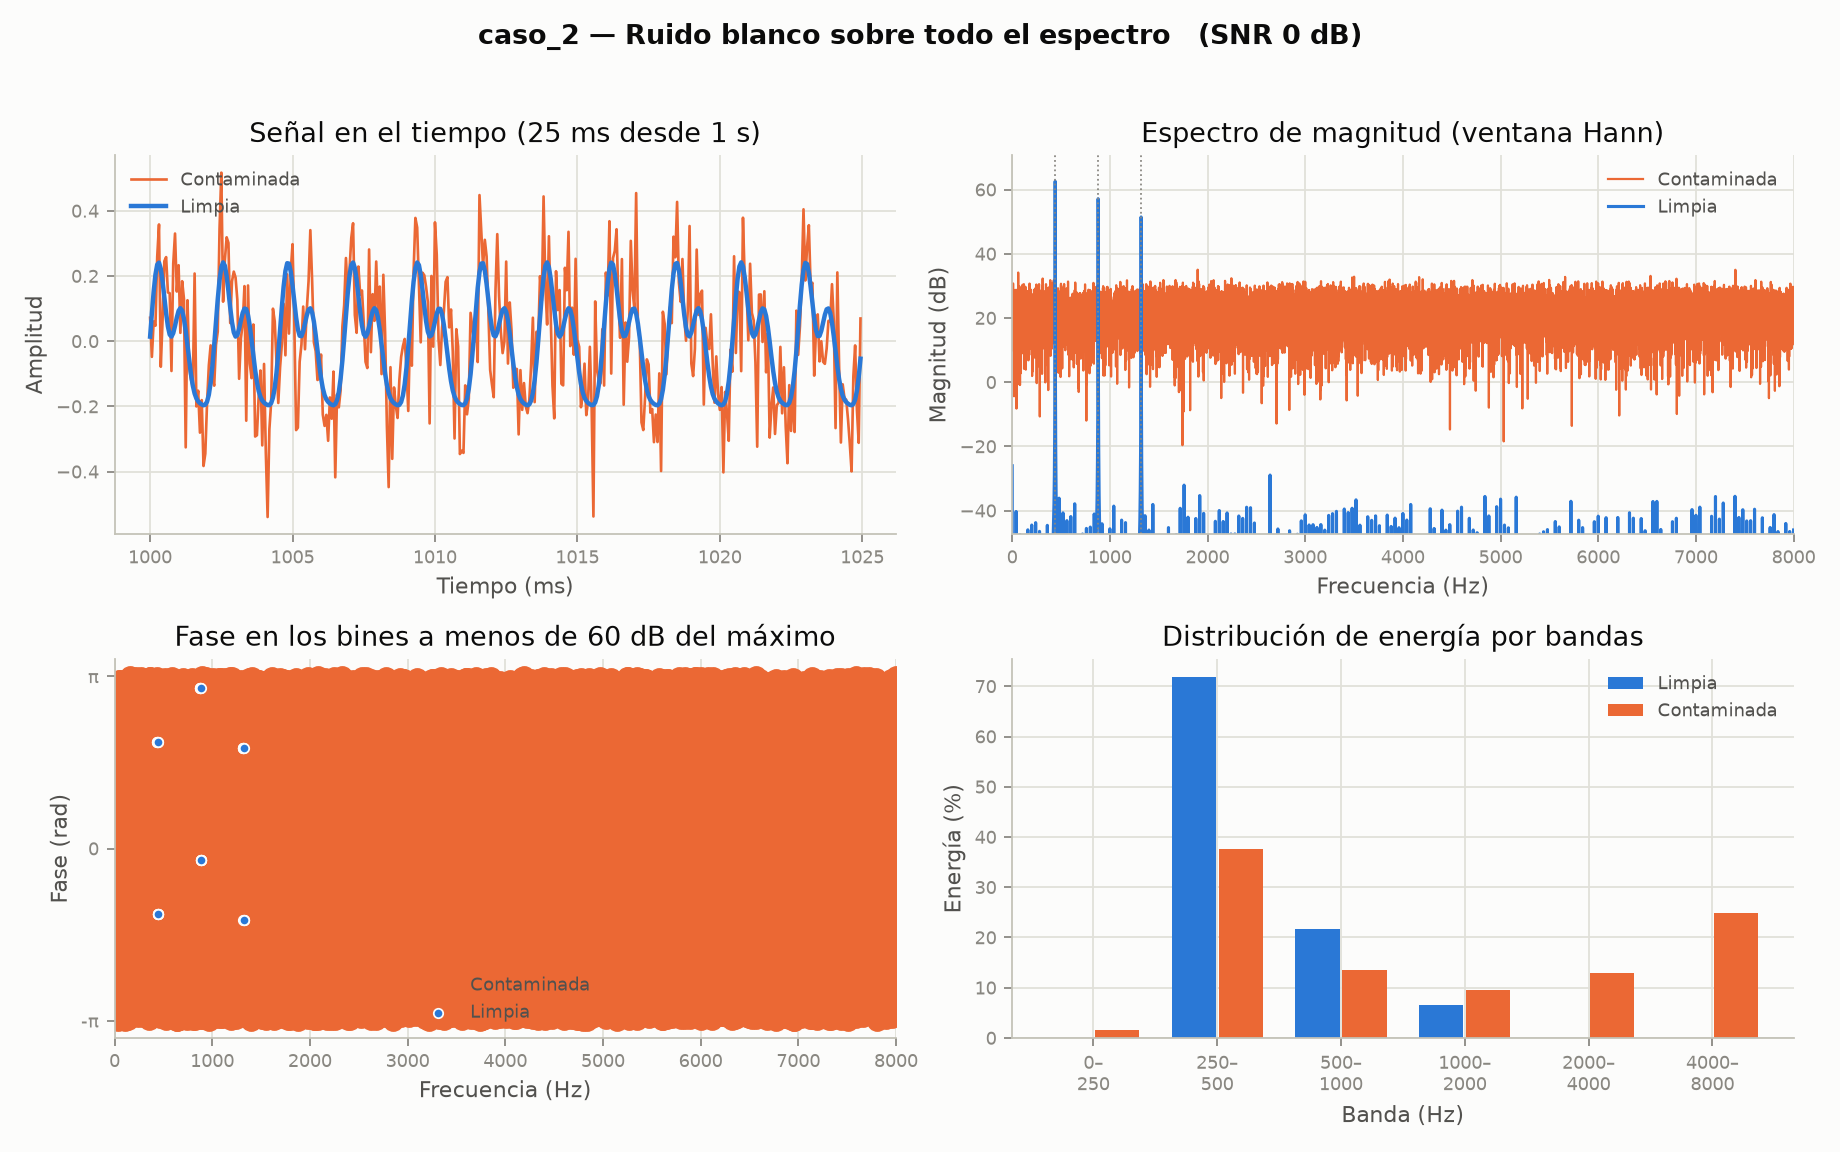

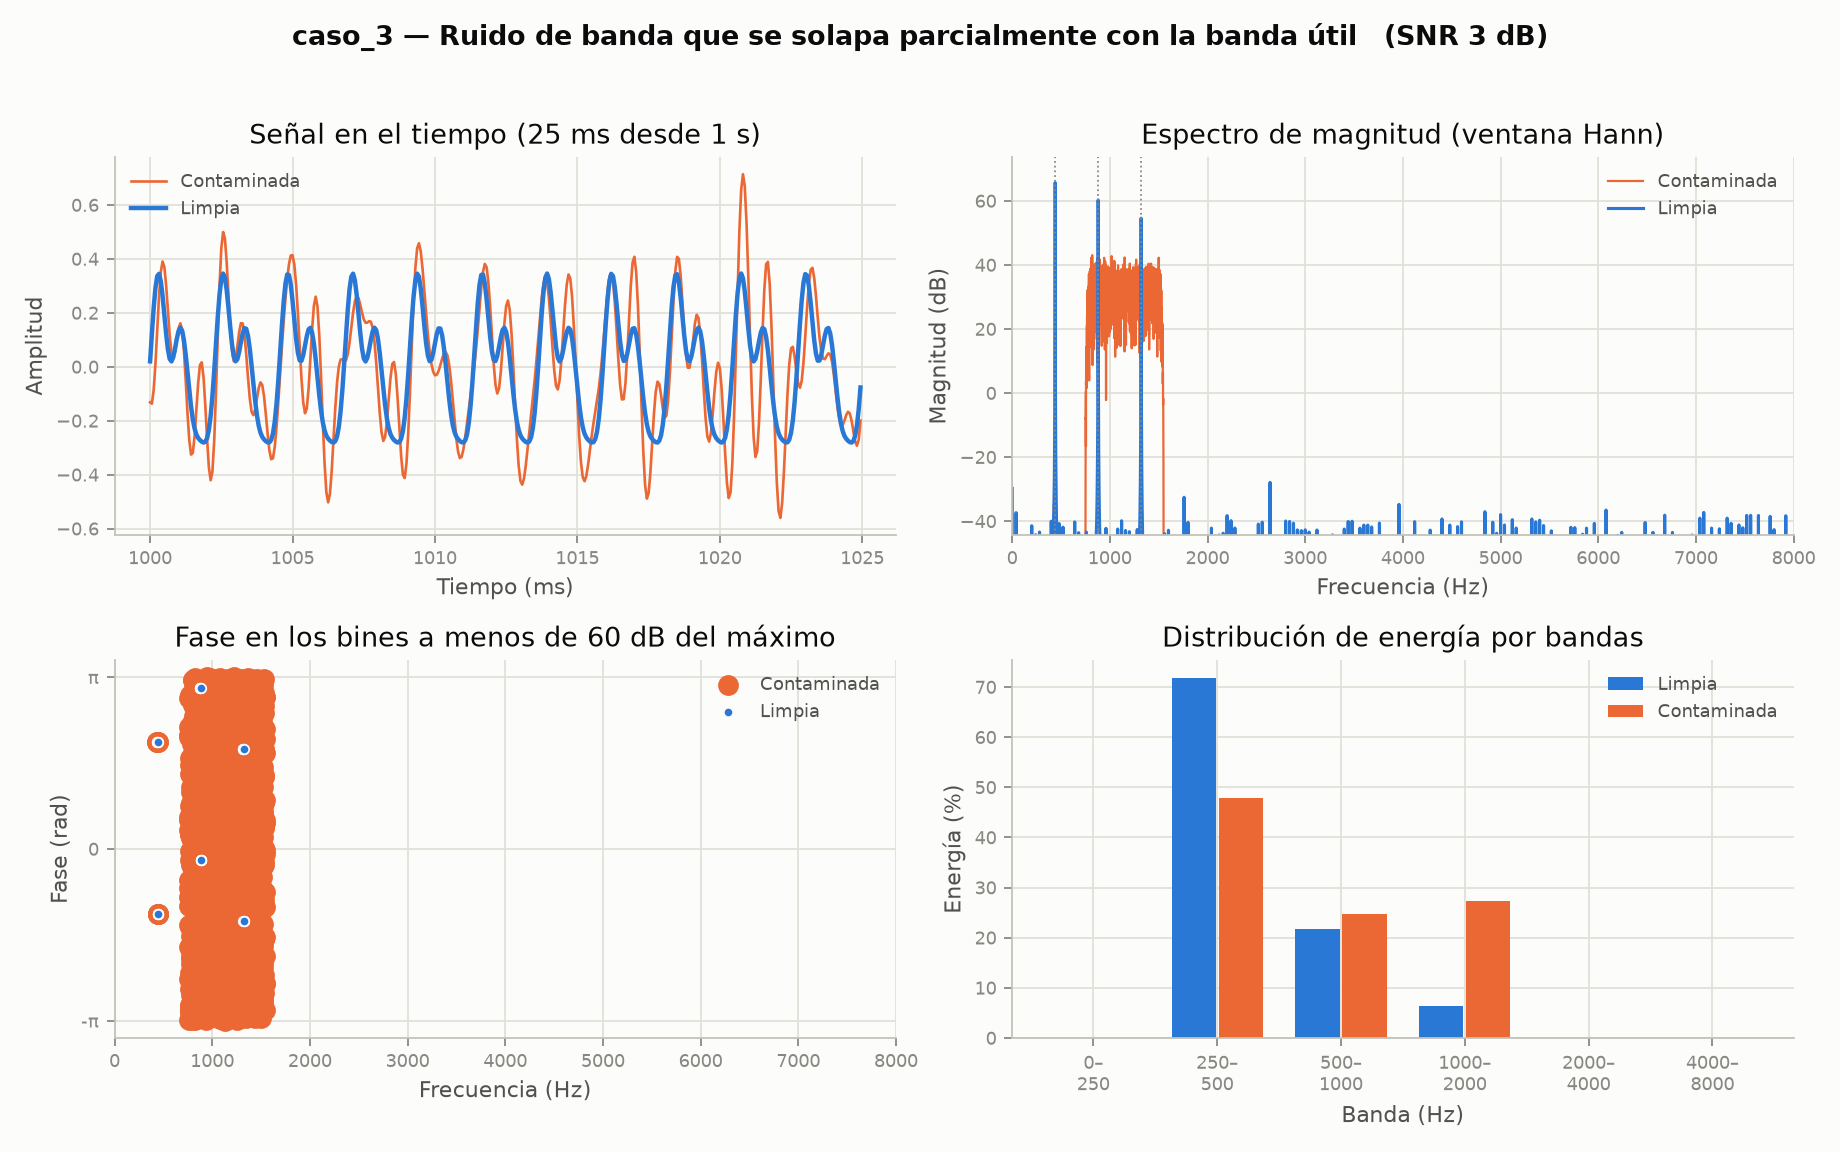

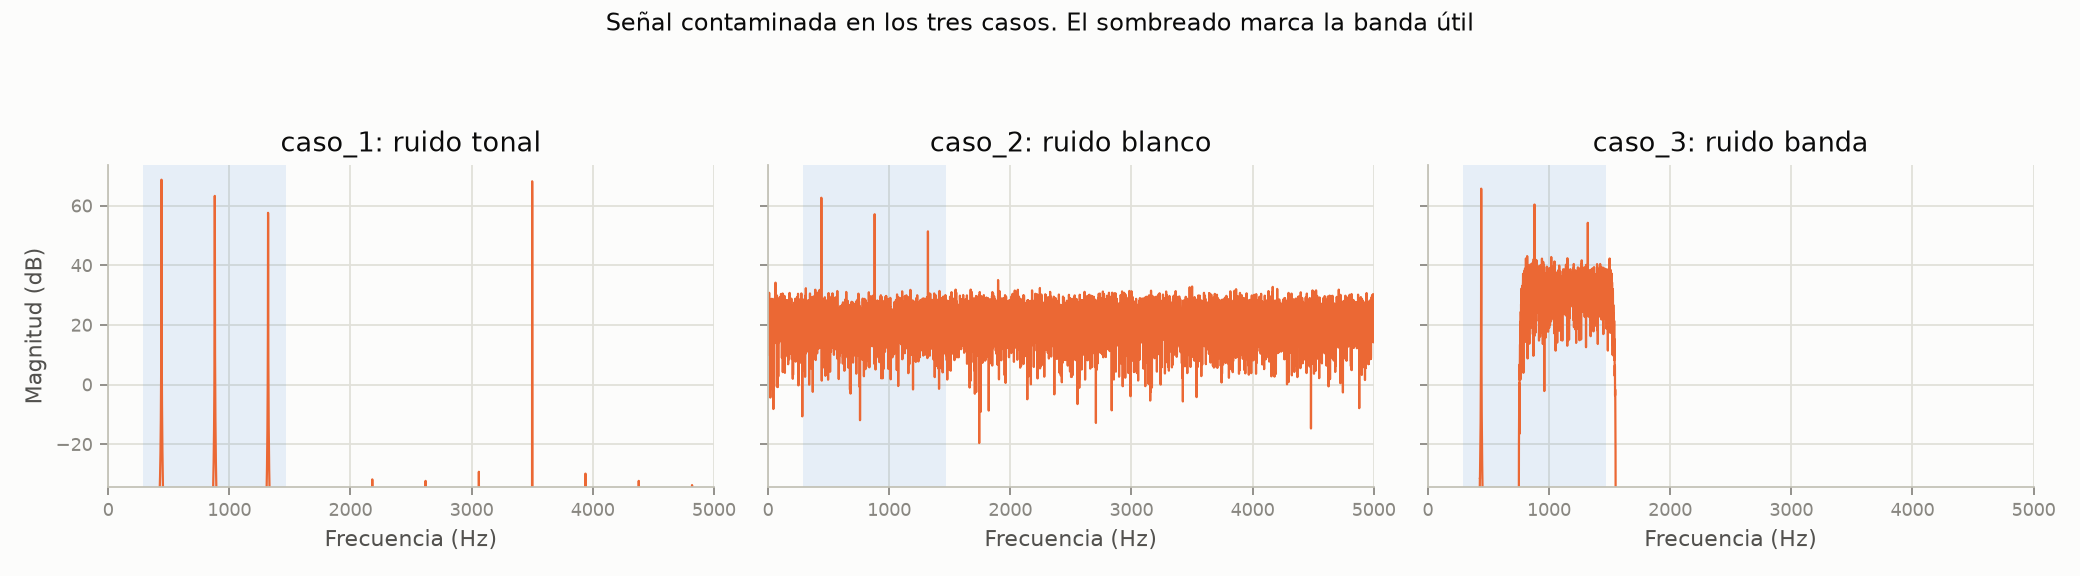

In [7]:
rutas = graficas.generar_todas(verbose=False)
for ruta in rutas:
    display(Image(filename=str(ruta)))

### 2.g Pruebas automáticas

In [8]:
sys.path.insert(0, str(RAIZ / 'pruebas'))
import test_senales

test_senales.main()

  ok   test_el_ruido_de_banda_queda_dentro_de_su_banda
  ok   test_el_ruido_tonal_concentra_su_energia_en_la_interferencia
  ok   test_la_contaminada_es_la_suma_de_las_otras_dos
  ok   test_la_cuantizacion_a_16_bits_apenas_mueve_la_snr
  ok   test_la_longitud_es_potencia_de_dos_y_cabe_un_numero_entero_de_bloques
  ok   test_la_misma_semilla_da_la_misma_senal
  ok   test_la_snr_obtenida_coincide_con_la_configurada
  ok   test_los_wav_conservan_frecuencia_y_longitud
  ok   test_ninguna_frecuencia_pasa_nyquist
  ok   test_no_hay_saturacion
  ok   test_semillas_distintas_dan_ruidos_distintos

11/11 pruebas pasan


0

## 3. Filtro temporal FIR o IIR

Apartado 2.3. Especificación de bandas, justificación del tipo y orden,
coeficientes, `H(z)`, polos y ceros, región de convergencia, estabilidad,
respuesta en magnitud, fase y retardo de grupo, y verificación de que la
ecuación de diferencias propia reproduce la salida de la biblioteca.



### 3.a Especificación y diseño

In [9]:
ID_FILTRO = 'caso_1'
FS = COMUN['fs_hz']
F_INT = CASOS[ID_FILTRO]['frecuencia_interferencia_hz']

ESPEC = dict(
    ftype='ellip',
    ws=[F_INT - 30, F_INT + 30],     # banda de rechazo (Hz)
    wp=[F_INT - 100, F_INT + 100],   # bordes de la banda de paso (Hz)
    gpass=1.0,                       # rizado máximo en paso (dB)
    gstop=40.0,                      # atenuación mínima en rechazo (dB)
)
sos, b, a = ft.disenar_iir(FS, **ESPEC)
print(f'f_int = {F_INT:.1f} Hz | secciones SOS = {len(sos)} | orden total = {a.size-1}')
for k, s in enumerate(sos):
    print(f'SOS {k}: b0={s[0]:+.8f} b1={s[1]:+.8f} b2={s[2]:+.8f} | a1={s[4]:+.8f} a2={s[5]:+.8f}')

f_int = 3500.0 Hz | secciones SOS = 3 | orden total = 6
SOS 0: b0=+0.91308167 b1=-0.35630097 b2=+0.91308167 | a1=-0.36307738 a2=+0.86089476
SOS 1: b0=+1.00000000 b1=-0.36230176 b2=+1.00000000 | a1=-0.31232631 a2=+0.98234956
SOS 2: b0=+1.00000000 b1=-0.41797720 b2=+1.00000000 | a1=-0.46016607 a2=+0.98261212


### 3.b Polos, ceros, ROC y estabilidad

Radio polar máximo = 0.991268 -> ROC causal: |z| > 0.991268
Contiene |z|=1: True | ESTABLE: True


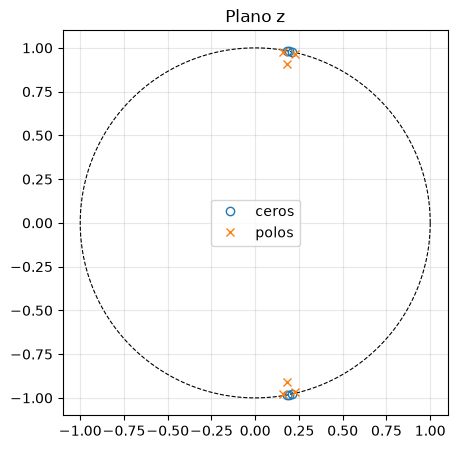

In [10]:
z, p, k = ft.zpk(sos)
estable, radio = ft.es_estable(sos)
print(f'Radio polar máximo = {radio:.6f} -> ROC causal: |z| > {radio:.6f}')
print('Contiene |z|=1:', radio < 1, '| ESTABLE:', estable)

fig, ax = plt.subplots(figsize=(5, 5))
t = np.linspace(0, 2*np.pi, 400)
ax.plot(np.cos(t), np.sin(t), 'k--', lw=.8)
ax.plot(z.real, z.imag, 'o', mfc='none', label='ceros')
ax.plot(p.real, p.imag, 'x', label='polos')
ax.set_aspect('equal'); ax.grid(alpha=.3); ax.legend(); ax.set_title('Plano z')
fig.savefig(CARPETA_FIGURAS / 'fig23_polos_ceros.png', dpi=150, bbox_inches='tight')
plt.show()

### 3.c Magnitud, fase y retardo de grupo

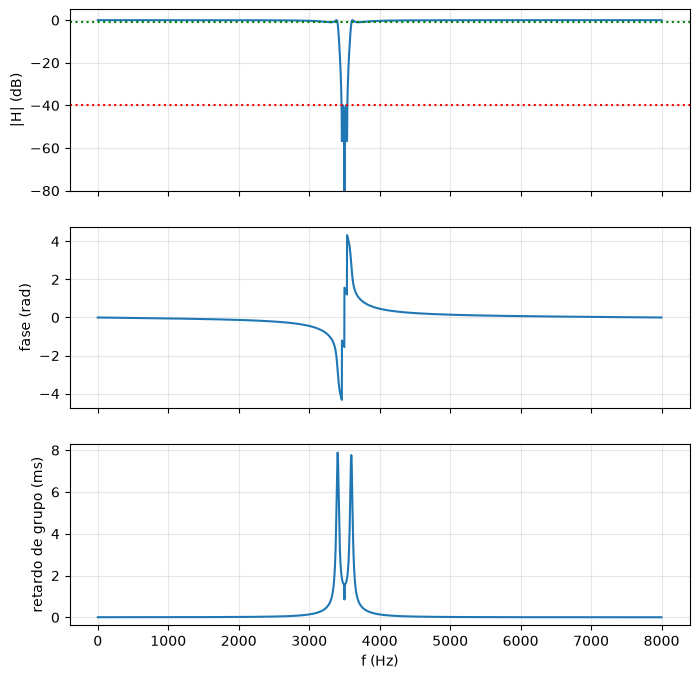

In [11]:
R = ft.respuestas(sos, FS)
fig, ax = plt.subplots(3, 1, figsize=(8, 8), sharex=True)
ax[0].plot(R['f'], R['mag_db']); ax[0].set_ylabel('|H| (dB)'); ax[0].set_ylim(-80, 5)
ax[0].axhline(-ESPEC['gpass'], ls=':', c='g'); ax[0].axhline(-ESPEC['gstop'], ls=':', c='r')
ax[1].plot(R['f'], R['fase']); ax[1].set_ylabel('fase (rad)')
ax[2].plot(R['f_gd'], R['gd_s']*1000); ax[2].set_ylabel('retardo de grupo (ms)')
ax[2].set_xlabel('f (Hz)')
for a_ in ax: a_.grid(alpha=.3)
fig.savefig(CARPETA_FIGURAS / 'fig23_filtro_respuestas.png', dpi=150, bbox_inches='tight')
plt.show()

### 3.d Ecuación de diferencias propia vs biblioteca (los tres casos)

In [12]:
TOL = 1e-9
for identificador in CASOS:
    x = senales.cargar_caso(identificador)['contaminada']
    v = ft.verificar_equivalencia(sos, b, a, x, tol=TOL)
    print(f"{identificador:8s} err(SOS)={v['err_max_sos']:.2e} err(b,a)={v['err_max_ba']:.2e} "
          f"tol={TOL:.0e} -> {'OK' if v['ok'] else 'FALLA'}")

caso_1   err(SOS)=0.00e+00 err(b,a)=2.81e-13 tol=1e-09 -> OK
caso_2   err(SOS)=0.00e+00 err(b,a)=1.86e-13 tol=1e-09 -> OK
caso_3   err(SOS)=0.00e+00 err(b,a)=1.90e-13 tol=1e-09 -> OK


### 3.e Aplicación a los tres casos y guardado de salidas

In [13]:
from scipy.io import wavfile

CARPETA_SALIDAS = RAIZ / 'resultados' / 'salidas'
CARPETA_SALIDAS.mkdir(parents=True, exist_ok=True)

print(f"{'caso':8s} {'SNR antes':>10s} {'SNR despues':>12s} {'mejora':>8s}  archivo")
N0 = 500   # se descarta el transitorio inicial al medir SNR
for identificador in CASOS:
    d = senales.cargar_caso(identificador)
    y = ft.filtrar_sos_manual(sos, d['contaminada'])   # sin compensar retardo
    antes = ft.snr_db(d['limpia'][N0:], d['contaminada'][N0:])
    despues = ft.snr_db(d['limpia'][N0:], y[N0:])
    ruta = CARPETA_SALIDAS / f'{identificador}_temporal.wav'
    wavfile.write(ruta, int(d['fs']),
                  np.round(np.clip(y, -1.0, 1.0 - 1/32768) * 32768).astype(np.int16))
    print(f'{identificador:8s} {antes:10.2f} {despues:12.2f} {despues-antes:+8.2f}  {ruta.name}')

caso      SNR antes  SNR despues   mejora  archivo
caso_1         2.03        30.13   +28.10  caso_1_temporal.wav
caso_2         0.03         0.22    +0.18  caso_2_temporal.wav
caso_3         3.01         3.02    +0.00  caso_3_temporal.wav


### 3.f Cuantización, saturación y memoria 

In [14]:
N_FREQ = 1 << 16
f, h = signal.sosfreqz(sos, worN=N_FREQ, fs=FS)
ref = 20*np.log10(np.abs(h) + 1e-15)
rech = (f >= ESPEC['ws'][0]) & (f <= ESPEC['ws'][1])
paso = (f <= ESPEC['wp'][0]) | (f >= ESPEC['wp'][1])

def metricas_respuesta(s):
    """Desviación máxima en banda de paso y peor |H| en banda de rechazo."""
    _, hq = signal.sosfreqz(s, worN=N_FREQ, fs=FS)
    mq = 20*np.log10(np.abs(hq) + 1e-15)
    return float(np.max(np.abs(mq[paso] - ref[paso]))), float(mq[rech].max())

variantes = [(f'Q{fb}', ft.cuantizar_sos(sos, fb)) for fb in (8, 12, 14, 16)]
variantes.append(('float32', sos.astype(np.float32).astype(np.float64)))

print('Cuantización de coeficientes (Qn = n bits fraccionarios)')
print(f"{'formato':>8s} {'estable':>8s} {'radio polar':>12s} "
      f"{'desv. paso':>11s} {'max|H| rechazo':>15s}")
for nombre, sq in variantes:
    estable_q, radio_q = ft.es_estable(sq)
    d_paso, m_rech = metricas_respuesta(sq)
    print(f"{nombre:>8s} {str(bool(estable_q)):>8s} {radio_q:12.6f} "
          f"{d_paso:8.3f} dB {m_rech:12.2f} dB")

print('\nMemoria y costo (4 bytes por coeficiente y por estado)')
mem = ft.memoria_bytes(sos, bytes_coef=4, bytes_estado=4)
print(f"secciones={mem['secciones']} | coeficientes={mem['coef_bytes']} B | "
      f"estados={mem['estado_bytes']} B | total={mem['total_bytes']} B")
print(f"{mem['MAC_por_muestra']} MAC/muestra -> "
      f"{mem['MAC_por_muestra']*FS:,.0f} MAC/s a fs={FS:.0f} Hz")

print('\nSaturación en int16 (escala Q1.14: 1.0 <-> 16384)')
print(f"{'caso':8s} {'pico |y|':>9s} {'saturaciones':>13s}")
for identificador in CASOS:
    y = ft.filtrar_sos_manual(sos, senales.cargar_caso(identificador)['contaminada'])
    print(f"{identificador:8s} {np.max(np.abs(y)):9.3f} "
          f"{ft.saturacion_int16(y, 2**14):13d}")

Cuantización de coeficientes (Qn = n bits fraccionarios)
 formato  estable  radio polar  desv. paso  max|H| rechazo
      Q8     True     0.992157    0.977 dB       -39.57 dB
     Q12     True     0.991295    0.034 dB       -39.96 dB
     Q14     True     0.991264    0.010 dB       -39.99 dB
     Q16     True     0.991264    0.005 dB       -40.00 dB
 float32     True     0.991268    0.000 dB       -40.00 dB

Memoria y costo (4 bytes por coeficiente y por estado)
secciones=3 | coeficientes=60 B | estados=24 B | total=84 B
15 MAC/muestra -> 240,000 MAC/s a fs=16000 Hz

Saturación en int16 (escala Q1.14: 1.0 <-> 16384)
caso      pico |y|  saturaciones
caso_1       0.490             0
caso_2       0.805             0
caso_3       0.795             0


## 4. Reducción espectral mediante FFT e IFFT

Apartado 2.4. Procesamiento por bloques de longitud potencia de dos con ventana,
FFT, estimación y modificación espectral, IFFT y reconstrucción con solapamiento.

*Pendiente — bloque 4.*

## 5. Comparación y propuesta para el sistema embebido

Apartado 2.5. Se comparan tres señales contra la referencia limpia: la
contaminada sin filtrar, la salida del filtro temporal y la salida del método
espectral. Antes de medir se compensa el retardo de cada método, estimado por
correlación cruzada, para que el MSE refleje distorsión y no retardo de grupo.

Las salidas las dejan los bloques 3 y 4 en `resultados/salidas/` con los nombres
`caso_N_temporal.wav` y `caso_N_espectral.wav`. Mientras falte alguna, la celda
reporta cuáles y arma la tabla con lo que haya.

In [15]:
import comparacion

filas = comparacion.main()

ModuleNotFoundError: No module named 'comparacion'

## 6. Exportación de resultados

`comparacion.main()` ya escribió `resultados/metricas.csv` y su versión alineada
en `resultados/metricas.txt`. Aquí solo se confirma qué quedó en el disco.

In [ ]:
for carpeta, patron in [('resultados', 'metricas.*'),
                       ('resultados/figuras', '*.png'),
                       ('resultados/salidas', '*.wav')]:
    archivos = sorted((RAIZ / carpeta).glob(patron))
    print(f'{carpeta}/{patron}: {len(archivos)} archivo(s)')
    for archivo in archivos:
        print(f'   {archivo.name:28s} {archivo.stat().st_size/1024:8.1f} KB')